In [32]:
import pandas as pd
import re
import matplotlib.pyplot as plt

In [6]:
recalls_a = pd.read_csv("../data/csv/recalls_2016_2021.csv")
recalls_b = pd.read_csv("../data/csv/recalls_2022_2025.csv")
recalls_c = pd.read_csv("../data/csv/recalls_2025_april.csv")

In [8]:
recalls_a_edit = recalls_a[["year", "date", "product_name"]]
recalls_b_edit = recalls_b[["year", "date", "product_name"]]
recalls_c_edit = recalls_c[["year", "date", "product_name"]]

In [56]:
stacked = pd.concat([recalls_a_edit, recalls_b_edit, recalls_c_edit], ignore_index=True)

In [57]:
stacked.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 169 entries, 0 to 168
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          169 non-null    int64 
 1   date          169 non-null    object
 2   product_name  169 non-null    object
dtypes: int64(1), object(2)
memory usage: 4.1+ KB


In [53]:
def fix_year_format(d):
    if pd.isna(d):  # skip missing
        return d
    # Match dd/mm/yy
    if re.match(r"\d{2}/\d{2}/\d{2}$", d):
        day, month, year = d.split("/")
        year = "20" + year if int(year) <= 25 else "19" + year  # adjust threshold as needed
        return f"{day}/{month}/{year}"
    return d

In [58]:
stacked["year"] = pd.to_datetime(stacked["year"],format="%Y")
stacked["date"] = stacked["date"].apply(fix_year_format)

In [59]:
stacked["year"] = stacked["year"].dt.date

In [60]:
stacked["date"] = pd.to_datetime(stacked["date"],format="%d/%m/%Y")
stacked["date"] = stacked["date"].dt.date

In [61]:
stacked = stacked.sort_values("date")

In [62]:
counts = stacked.groupby(["date", "product_name"]).size().reset_index(name="count")

In [63]:
pivot = counts.pivot(index="date", columns="product_name", values="count").fillna(0)
print(pivot)


product_name  8-0  Blue twisted silk suture  ABZ tablet  APC Tablets  \
date                                                                   
2013-12-11                              0.0         0.0          0.0   
2015-09-24                              0.0         0.0          0.0   
2016-06-15                              0.0         0.0          0.0   
2017-03-29                              0.0         0.0          0.0   
2017-04-05                              0.0         0.0          0.0   
...                                     ...         ...          ...   
2025-03-11                              0.0         0.0          0.0   
2025-03-19                              0.0         0.0          0.0   
2025-03-21                              0.0         0.0          0.0   
2025-04-03                              0.0         0.0          0.0   
2025-04-24                              0.0         0.0          0.0   

product_name  Acepril 5mg  Alben oral suspension  \
date       

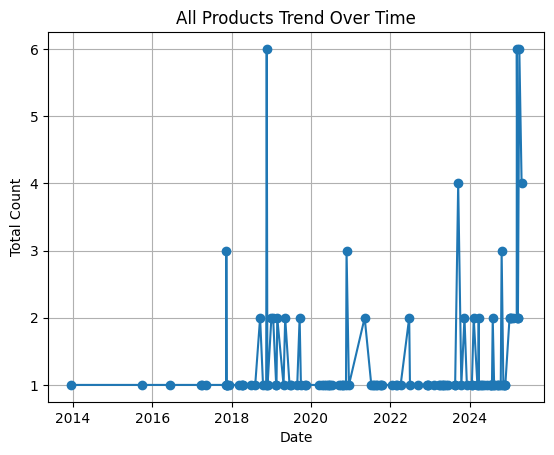

In [65]:
daily_totals = stacked.groupby("date").size()

# Plot
daily_totals.plot(kind="line", marker="o")
plt.title("All Products Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Total Count")
plt.grid(True)
plt.show()